Trabajo Práctico Final

Nombre y Apellido: Pablo Delucchi

Curso: Herramientas básicas para Análisis de Datos

Fecha de entrega: 10-11-2026

# **Análisis del mercado argentino de peróxido de hidrógeno (2021-2026)**                                           

 Descripción general: El consumo de agua oxigenada tiene múltiples aplicaciones además del uso más conocido en farmacia. Está directamente ligado al crecimiento de diversas industrias, especialmente la del papel, textil, minería y envasado de alimentos.

Siendo uno de los mayores fabricantes de este insumo,es primordial monitorear nuestra posición en el mercado analizando periódicamente las importaciones de la posición arancelaria correspondiente, así como incluir con la mayor precisión posible las cantidades fabricadas en el país.                                                                  
Objetivos principales: Hacer el seguimiento a lo largo de los últimos 5 años de los siguientes indicadores
#1) Evolución del tamaño del mercado en toneladas y participación de cada empresa
#2) Evolución de los precios y comparación frente a la competencia
#3) Incidencia del costo logístico en el precio del producto






#**Evaluación de viabilidad del análisis de los datos**

Las columnas Importer, Net Weight,US$ CIF, Freight, Date e Insurance, mediante cálculos que se harán a continuación permiten responder los 3 objetivos.



# **Origen de los datos**
Servicio de datos de comercio exterior llamado Penta Transaction
https://app.penta-transaction.com/home/detalle/AR/importDetalladas

requiere acceso con contraseña y usuario, se descargan por año las importaciones de la posición arancelaria del peróxido de hidrógeno (código 2847) y se arma el archivo H2O2 2021 - Sep 2026_sucio.xlsx, que unifica todos los despachos de importaciones en el período 2021 - Sep 2026. Es factible mensual o trimestralmente, incorporar los nuevos datos y actualizar todo el análisis.

#**Carga del dataset y prospección inicial**

In [1]:
#Importacion de librerias
import pandas as pd
import numpy as np


In [2]:
# Importamos drive para acceder al dataset
from google.colab import drive
drive.mount('/content/drive')

# Apuntamos a la ruta del archivo correcto en Google Drive
ruta_archivo = "/content/drive/MyDrive/HB- AD UTN/H2O2 2021- Sep 2026_sucio.xlsx"

Mounted at /content/drive


##Estudio preliminar del dataset

In [3]:

df = pd.read_excel(ruta_archivo) # Definición de la variable df, con la que trabajará Python en todo el análisis
print(df.shape, "Filas","Columnas")  # Dimensiones del dataset


(5848, 36) Filas Columnas


In [4]:
# Chequeo rápido de tipos de datos (objetos,fechas, valores enteros y decimales) y si hay datos sin definir (espacios en blanco) o bien nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5848 entries, 0 to 5847
Data columns (total 36 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Identifier                 5848 non-null   object        
 1   Item                       5848 non-null   int64         
 2   Date                       5848 non-null   datetime64[ns]
 3   Datatype                   5848 non-null   object        
 4   NCM-SIM                    5848 non-null   object        
 5   Importer                   5848 non-null   object        
 6   Location                   5848 non-null   object        
 7   Destination                5848 non-null   object        
 8   Customs                    5848 non-null   object        
 9   Via Transporte             5848 non-null   object        
 10  Origin Country             5848 non-null   object        
 11  Departure Country          5848 non-null   object        
 12  U$S Un

Muestra que las columnas que indican cantidades, hay números, las que indican alguna característica son texto, las fechas tienen el formato correcto

In [5]:
df.tail() # Últimas 5 filas del dataset

,Identifier,Item,Date,Datatype,NCM-SIM,Importer,Location,Destination,Customs,Via Transporte,...,Item2,Brand - Suffixes,Quantity3,Currency Unit,FOB Currency,Currency,Sales Condition,Brand or Description,Descripcion Arancelaria,Model
5843,26042IC05025814V,1,2026-09-29,DEFINITIVO,2847.00.00.000G,INDAQUIM S A,SANTA FE,CONSUMO,PASO DE LOS LIBRES,CAMION,...,0,MARCA: PEROXIDO,26400.0,0.49,13035.26,DOLAR USA,CIP,ZA(000060)-AA(PEROXIDO)-AI(S/CODIGO)-AJ(CONTEN...,"PEROXIDO DE HIDROGENO, AGUA OXIGENADA",Not available
5844,26073IC04106953F,16,2026-09-29,DEFINITIVO,2847.00.00.000G,SIGMA ALDRICH DE ARGENTINA S A,CAPITAL FEDERAL,CONSUMO,EZEIZA,AVION,...,0,MARCA: SIGMA,1.0,18.96,18.96,DOLAR USA,CPT,AA(SIGMA)-AI(88597 100ML F)-AJ(ENVASES X 100 M...,"PEROXIDO DE HIDROGENO, AGUA OXIGENADA",Not available
5845,26042IC05026010K,1,2026-09-30,DEFINITIVO,2847.00.00.000G,SOLVAY PERàXIDOS DEL PLATA SRL,CIUDAD AUTONOMA,CONSUMO,PASO DE LOS LIBRES,CAMION,...,1,MARCA: INTEROX,2240.0,0.58,1310.40,DOLAR USA,CIP,ZA(000060)-AA(INTEROX)-AI(S/C)-AJ(BIDONES)-`,"PEROXIDO DE HIDROGENO, AGUA OXIGENADA",Not available
5846,26042IC05026010K,1,2026-09-30,DEFINITIVO,2847.00.00.000G,SOLVAY PERàXIDOS DEL PLATA SRL,CIUDAD AUTONOMA,CONSUMO,PASO DE LOS LIBRES,CAMION,...,2,MARCA: INTEROX,24000.0,0.39,9480.00,DOLAR USA,CIP,ZA(000060)-AA(INTEROX)-AI(S/C)-AJ(IBC)-`,"PEROXIDO DE HIDROGENO, AGUA OXIGENADA",Not available
5847,26057IC03000024L,1,2026-09-30,DEFINITIVO,2847.00.00.000G,DALGAR S A,9 DE ABRIL,CONSUMO,SAN LORENZO,CAMION,...,0,MARCA: S/M,55.5,330.00,18315.00,DOLAR USA,FCA,ZA(000060)-AA(S/M)-AI(HYDROGEN PEROXIDE)-AJ(IS...,"PEROXIDO DE HIDROGENO, AGUA OXIGENADA",Not available


No hay totales, filas vacías ni nada anómalo que pueda distorsionar los cálculos que se harán luego para el análisis

Luego de estos pasos, comienzo con la identificación de filas innecesarias/sin sentido y luego se toma la decisión de eliminarlas o qué hacer con esas filas

In [6]:
print("Filas duplicadas", (df.duplicated().sum()))

Filas duplicadas 0


In [7]:
# Valores nulos en columnas específicas

nulos = (df['Net Weight'] == 0).sum()
print(f"Cantidad de filas con valor cero en 'Net Weight': {nulos}")

Cantidad de filas con valor cero en 'Net Weight': 171


Aviso de que se necesita investigar si hay inconsitencia de datos

In [8]:
# Columnas sin utilidad (varianza nula)
unicos= df.nunique()
columnas_varianza_nula = unicos[unicos<= 1].index.tolist()
print(columnas_varianza_nula)

['Datatype', 'NCM-SIM', 'Right', '% Dere.', 'ALADI Agreement', 'Descripcion Arancelaria', 'Model']


Por lo que informan estas columnas, en este dataset es irrelevante y no hay que eliminar ninguna

Corrección de sintaxis:
Al hacer la prospección del dataset sucio, está mal escrito el nombre de la empresa en la que trabajo, procedo a corregirlo para que los gráficos posteriores aparezcan correctamente

In [9]:
import pandas as pd
import numpy as np

# 1. Asegurar columna de período temporal 'anio_mes' y conversión de fecha
df['Date'] = pd.to_datetime(df['Date'])
df['anio_mes'] = df['Date'].dt.to_period('M').astype(str)

# Corregir el nombre del importador 'Solvay Peráxidos' a 'Solvay Peróxidos' usando expresiones regulares estándar libres de bytes nulos
df['Importer'] = df['Importer'].str.replace('SOLVAY PER.XIDOS DEL PLATA SRL', 'SOLVAY PEROXIDOS DEL PLATA SRL', case=False, regex=True)



También se detectó que la columna Net Weight está en kg y se pasará todo a toneladas porque es más conveniente para el análisis

In [10]:
# Convertimos la columna 'Net Weight' de kg a toneladas
df['Net Weight'] = df['Net Weight'] / 1000.0



Hasta aquí se analizó en forma preliminar los datos originales, sin eliminar/limpiar nada.
Ahora se procederá a crear/definir nuevas columnas, que son cálculos de las ya existentes, necesarias para el análisis de datos.
También se decidirá si se eliminan filas

Nuevas columnas:
Precio CIF Unitario (USD/tn) y
Freight (USD/tn)

# Adaptación del dataset para responder a los objetivos (Limpieza y agregado de otros datos sobre producción nacional)

###Creación de las nuevas columnas que responderán a los objetivos del análisis y filtrado previo de las mismas

In [11]:
# Para calcular el precio unitario correcto usando las columnas existentes:
# Colocamos los nombres de las columnas siempre entre comillas dentro de los corchetes
df['Precio CIF USD/tn'] = df['U$S CIF'] / df['Net Weight']

print(df['Precio CIF USD/tn'])

0          518.604938
1          534.160400
2          632.642130
3          646.400000
4          518.760000
            ...      
5843       625.000000
5844    195600.000000
5845       539.656631
5846              NaN
5847       340.579279
Name: Precio CIF USD/tn, Length: 5848, dtype: float64


In [12]:
# Contamos los valores nulos en la nueva columna de precio unitario
nulos = df['Precio CIF USD/tn'].isna().sum()
print(f"Valores nulos en Precio CIF USD/tn: {nulos}")

Valores nulos en Precio CIF USD/tn: 171


In [13]:
# Para calcular la incidencia del costo logístico en el precio del producto creamos la columna Freight/tn
df['Freight USD/tn'] = df['Freight U$S'] / df['Net Weight']

print(df['Freight USD/tn'])

0        125.000000
1        127.610000
2        225.185185
3        147.490152
4        182.640000
           ...     
5843     131.070076
5844    4900.000000
5845     128.288110
5846            NaN
5847       7.207207
Name: Freight USD/tn, Length: 5848, dtype: float64


In [14]:
# Contamos los valores nulos en la nueva columna Freigth USD/tn
nulos = df['Freight USD/tn'].isna().sum()
print(f"Valores nulos en Freight USD/tn: {nulos}")

Valores nulos en Freight USD/tn: 171


Como esta columna se construye con la de "Net Weight" las filas nulas son también 171

###**Criterio adicional de limpieza/clasificación correcta de los datos**

Por conocimiento de las aplicaciones, se sabe que los laboratorios farmacéuticos importan muestras de agua oxigenada, son cantidades muy pequeñas, y como vienen por via aérea tienen precios muy altos, son cantidades que "ensucian" el análisis.
Se procederá a identificar estos datos, filtrandolos por precio y luego se eliminarán estas filas

In [15]:
# Definimos el valor límite para el filtro por precio
valor_limite = 1100

# Filtramos las filas donde 'Precio CIF USD/tn' sea mayor que el límite
df_filtrado_mayor = df[df['Precio CIF USD/tn'] > valor_limite]

# Mostramos los resultados
print(f"Filas totales: {df.shape[0]}")
print(f"Filas con Precio CIF USD/tn mayor a {valor_limite}: {df_filtrado_mayor.shape[0]}")


Filas totales: 5848
Filas con Precio CIF USD/tn mayor a 1100: 372


In [16]:
# Sobreescribimos df quitando las filas con precios y cantidades anómalas
df = df[df['Precio CIF USD/tn'] <= 1100]


# Verificamos la nueva cantidad de filas
print(f"Nueva cantidad de filas en df: {df.shape[0]}")

Nueva cantidad de filas en df: 5305


De las 5848 filas originales, se eliminaron 171 donde la cantidad es nula y 372 filas donde el precio es mayor a 1.100 usd/tn, quedando 5305 filas

### Incorporación del único producto local (Atanor) al dataset

El dataset es de importaciones pero también hay un productor local, del que no hay datos, pero se conoce por hablar con los clientes, su producción anual en forma bastante precisa, por lo que se agregará 1 fila en cada mes y por cada año del volumen de esta empresa.

PRECIOS: NO SE INCLUIRÁN EN EL ANÁLISIS PORQUE NO SE DISPONE DE INFORMACIÓN PRECISA Y PORQUE EN EL DATASET SON VALORES CIF/TN Y LOS PRECIOS DE ATANOR SON LOCALES (YA INCLUYEN MARGEN DE VENTA+IVA) POR LO QUE LA COMPARACION NO ES REALISTA.

Sí se hará una comparación de los precios de producto importado





In [17]:
import pandas as pd
import numpy as np

# 1. Asegurar columna de período temporal 'anio_mes'
df['anio_mes'] = df['Date'].dt.to_period('M').astype(str)

# 2. Limpiar registros previos de ATANOR para evitar duplicación
df = df[df['Importer'] != 'ATANOR'].copy()

# 3. Generar filas mensuales dinámicas para Atanor
meses_unicos = df['Date'].dt.to_period('M').unique()
filas_atanor = []

for periodo in meses_unicos:
    fecha_mes = periodo.to_timestamp()
    anio = fecha_mes.year
    mes = fecha_mes.month

    # Filtrar solo enero a septiembre en 2026
    if anio == 2026 and mes > 9:
        continue

    # Asignar toneladas mensuales distribuyendo el volumen anual
    if anio in [2021, 2022, 2025]:
        toneladas_mensuales = 12500 / 12
    elif anio in [2023, 2024]:
        toneladas_mensuales = 11600 / 12
    elif anio == 2026:
        toneladas_mensuales = 9375 / 9
    else:
        toneladas_mensuales = 1000.0

    peso_neto_mensual = toneladas_mensuales

    filas_atanor.append({
        'Date': fecha_mes,
        'Anio': anio,
        'anio_mes': str(periodo),
        'Importer': 'ATANOR',
        'Net Weight': peso_neto_mensual,
        'Origin Country': 'ARGENTINA'  # Seteamos el origen siempre como ARGENTINA
    })

# 4. Combinar con el dataset original
df_atanor = pd.DataFrame(filas_atanor)
df = pd.concat([df, df_atanor], ignore_index=True)

# Mostrar confirmación y primeras líneas del productor local incorporado
print(f"Se incorporaron correctamente {len(df_atanor)} registros mensuales de ATANOR.")
display(df[df['Importer'] == 'ATANOR'][['Date', 'Importer', 'Net Weight', 'Origin Country']].head())

Se incorporaron correctamente 69 registros mensuales de ATANOR.


,Date,Importer,Net Weight,Origin Country
5305,2021-01-01,ATANOR,1041.666667,ARGENTINA
5306,2021-02-01,ATANOR,1041.666667,ARGENTINA
5307,2021-03-01,ATANOR,1041.666667,ARGENTINA
5308,2021-04-01,ATANOR,1041.666667,ARGENTINA
5309,2021-05-01,ATANOR,1041.666667,ARGENTINA


# Finalización limpieza y ajuste dataset
Hasta aquí la limpieza y ordenamiento de los datos y la inclusión de los datos del fabricante local, que por su alta participación en el mercado es esencial considerarlos y asumir hipótesis de sus volúmenes de producción/venta.
De 5848 filas originales, luego de la limpieza,quedaron 5305 y con el agregado de las de producción nacional resultan en 5374, que son las filas que se considerarán para el análisis de datos

#Confección de gráficos que respondan a las preguntas objetivo descriptas al inicio

In [18]:
#Importación de librerias para graficar
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as plt

## Gráfico de cantidades del mercado de peróxido de hidrógeno (Imports+Prod local) (Obj 1)

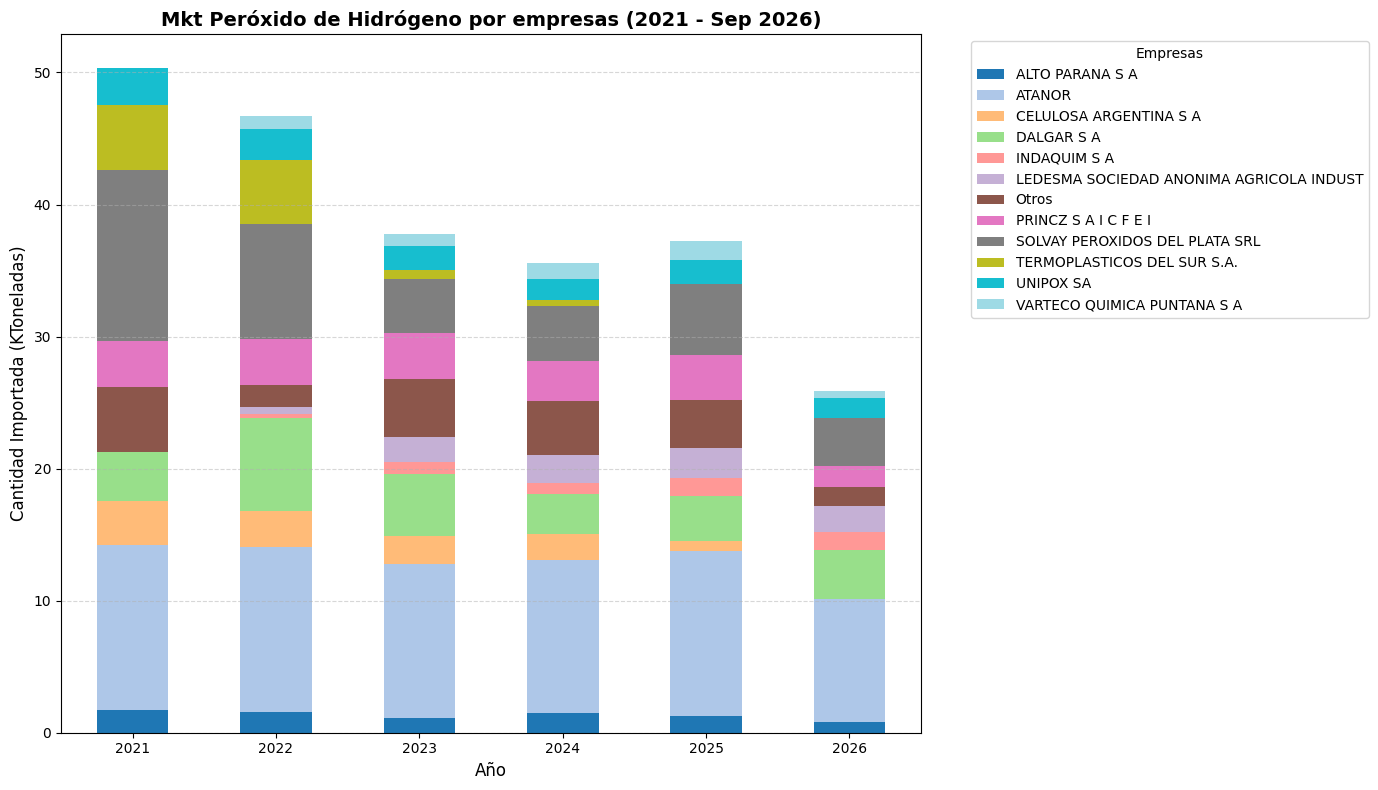

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Aseguramos extraer el año de la columna 'Date'
df['Anio'] = df['Date'].dt.year

# 2. Identificamos los importadores principales (por ejemplo, aquellos con > 2% del total global de importaciones)
volumen_total_por_importer = df.groupby('Importer')['Net Weight'].sum()
limite_volumen = 0.02 * volumen_total_por_importer.sum()
importers_principales = volumen_total_por_importer[volumen_total_por_importer >= limite_volumen].index

# Creamos una columna temporal con nombres simplificados
df['Importer_Simplificado'] = df['Importer'].apply(lambda x: x if x in importers_principales else 'Otros')

# 3. Agrupamos por Año e Importador Simplificado para sumar los Kilogramos ('Net Weight')
df_agrupado = df.groupby(['Anio', 'Importer_Simplificado'])['Net Weight'].sum().reset_index()

# Convertimos el peso neto a Toneladas (opcional, para que los números del eje Y sean más legibles)
df_agrupado['Toneladas'] = df_agrupado['Net Weight'] / 1000

# 4. Pivotamos la tabla para que los importadores sean las columnas y los años el índice
df_pivot = df_agrupado.pivot(index='Anio', columns='Importer_Simplificado', values='Toneladas').fillna(0)

# 5. Dibujamos el gráfico de barras apiladas
ax = df_pivot.plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

plt.title("Mkt Peróxido de Hidrógeno por empresas (2021 - Sep 2026)", fontsize=14, fontweight='bold')
plt.xlabel("Año", fontsize=12)
plt.ylabel("Cantidad Importada (KToneladas)", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Posicionamos la leyenda fuera del gráfico para que no tape las barras
plt.legend(title="Empresas", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Gráfico que permite contabilizar el volumen total. Desde 2023 la tendencia es bajista, consecuencia de la apertura de importaciones y caída progresiva del consumo.
Como el año 2026 no ha concluído, a continuación se hace otra gráfica comparando de Ene a Sep de cada año.

```markdown
## Gráfico Comparativo Acumulado (Enero - Septiembre) para Todos los Años



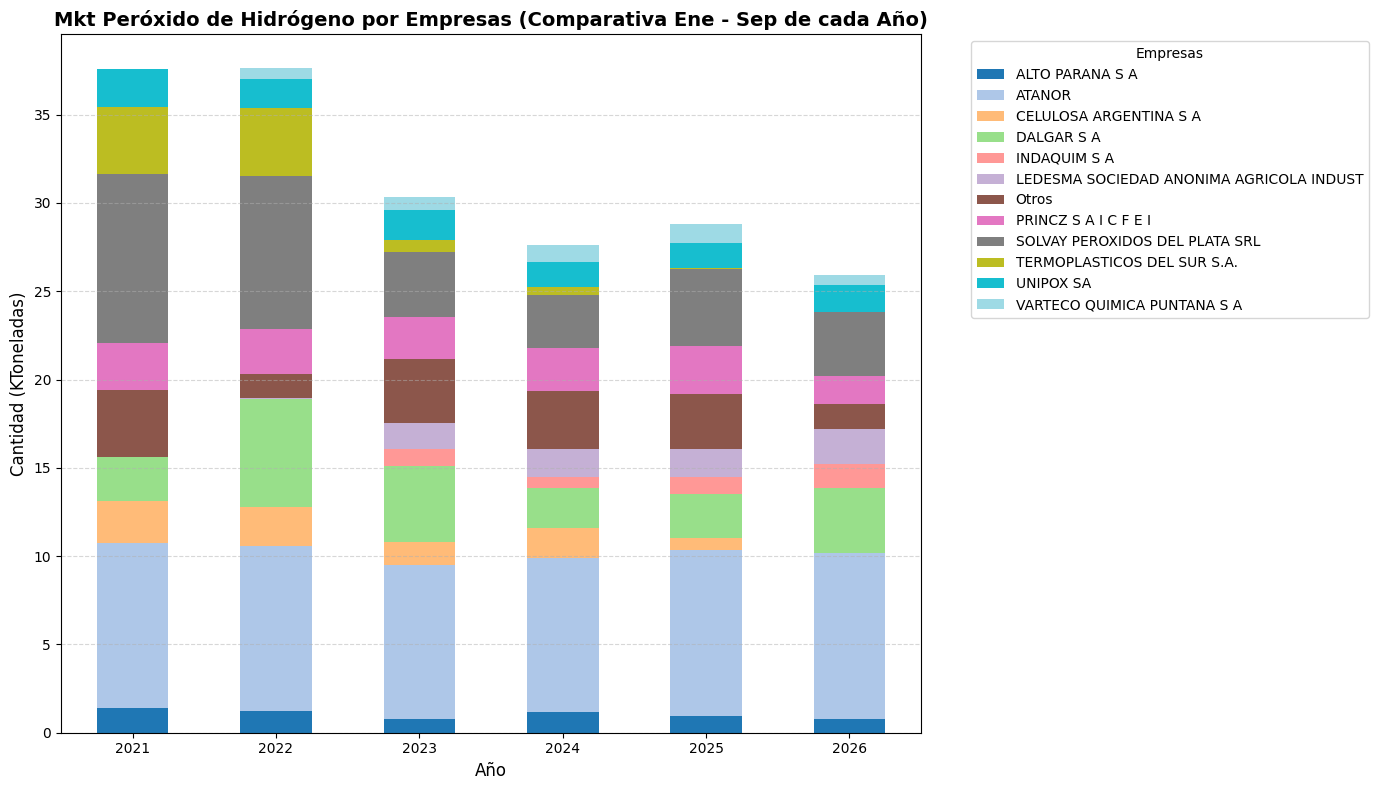

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Aseguramos extraer el mes y el año de la columna 'Date'
df['Mes'] = df['Date'].dt.month
df['Anio'] = df['Date'].dt.year

# 2. Filtramos el DataFrame para conservar solo los meses de enero a septiembre (1 al 9) de cada año
df_ene_sep = df[df['Mes'] <= 9].copy()

# 3. Identificamos los importadores principales basados en este volumen específico filtrado
volumen_total_por_importer = df_ene_sep.groupby('Importer')['Net Weight'].sum()
limite_volumen = 0.02 * volumen_total_por_importer.sum()
importers_principales = volumen_total_por_importer[volumen_total_por_importer >= limite_volumen].index

# Creamos una columna simplificada para agrupar los minoritarios bajo 'Otros'
df_ene_sep['Importer_Simplificado'] = df_ene_sep['Importer'].apply(lambda x: x if x in importers_principales else 'Otros')

# 4. Agrupamos por Año e Importador Simplificado y convertimos a Toneladas
df_agrupado_es = df_ene_sep.groupby(['Anio', 'Importer_Simplificado'])['Net Weight'].sum().reset_index()
df_agrupado_es['KToneladas'] = df_agrupado_es['Net Weight'] / 1000.0

# 5. Pivotamos la tabla para graficar de forma apilada
df_pivot_es = df_agrupado_es.pivot(index='Anio', columns='Importer_Simplificado', values='KToneladas').fillna(0)

# 6. Dibujamos el gráfico de barras apiladas
ax_es = df_pivot_es.plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

plt.title("Mkt Peróxido de Hidrógeno por Empresas (Comparativa Ene - Sep de cada Año)", fontsize=14, fontweight='bold')
plt.xlabel("Año", fontsize=12)
plt.ylabel("Cantidad (KToneladas)", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Posicionamos la leyenda de manera clara fuera del gráfico
plt.legend(title="Empresas", bbox_to_anchor=(1.05, 1), loc='upper left')

# Agregamos el total por año sobre cada columna
for idx, rect in enumerate(ax_es.patches):
    # Opcional: Podríamos agregar etiquetas de volumen acumulado si fuera necesario
    pass

plt.tight_layout()
plt.show()

Se observa que el mercado viene disminuyendo desde el 2023 por dificultades para importar en ese año y luego desde 2024 por la caída del consumo (industrias textil, papel, limpieza, entre otras)
No surgieron nuevos jugadores en el mercado.
Se observa la tendencia que el 2026 el tamaño del mercado será menor a cualquiera de los otros años.

## Gráfico Top 5 Empresas por Año (% Mkt Share) (Obj 1)

El siguiente código calcula la participación porcentual de cada empresa sobre el total de kilogramos ingresados en cada año calendario, selecciona los 5 líderes de cada período y genera gráficos individuales por año.

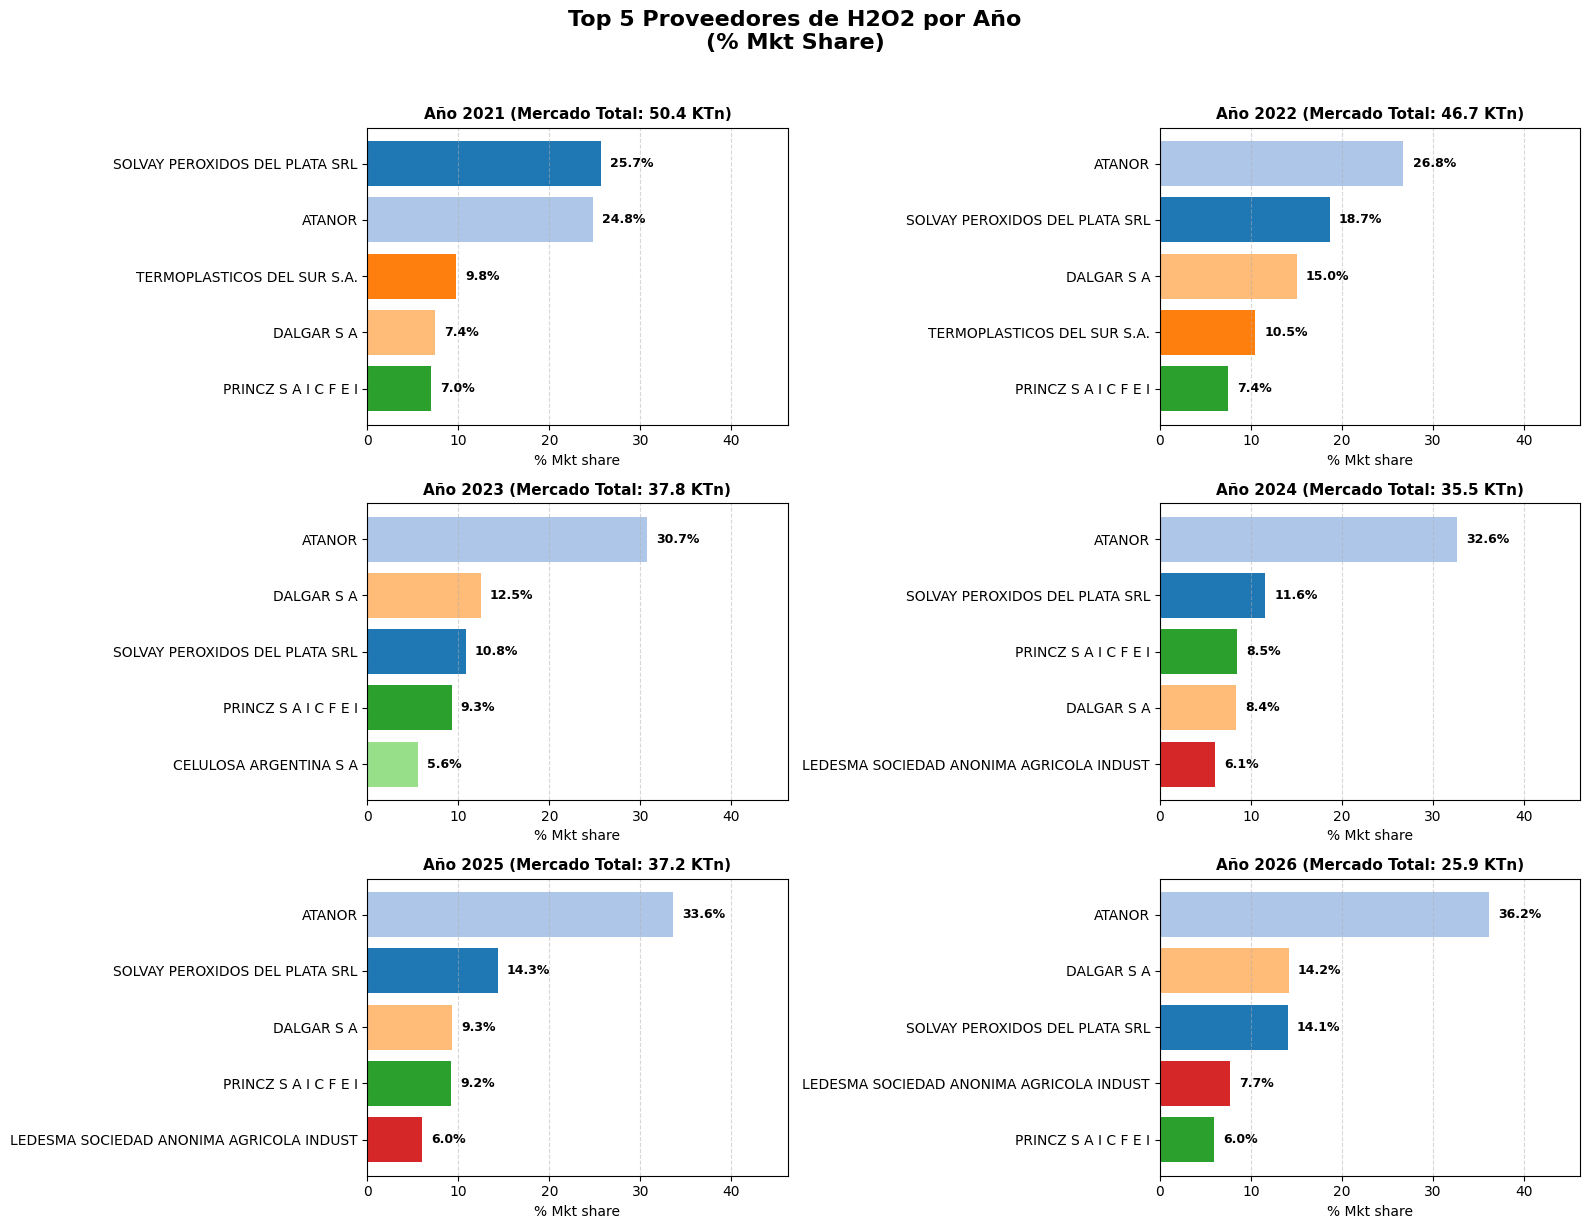

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aseguramos que la columna 'Anio' esté en el DataFrame
if 'Anio' not in df.columns:
    df['Anio'] = df['Date'].dt.year

# 2. Agrupamos por Año e Importador para obtener la suma de peso neto
df_anual = df.groupby(['Anio', 'Importer'])['Net Weight'].sum().reset_index()

# 3. Calculamos el total anual para obtener el porcentaje y las toneladas totales
totales_anuales = df.groupby('Anio')['Net Weight'].sum().reset_index().rename(columns={'Net Weight': 'Total_Anio'})
totales_anuales['Total_Anio_Tn'] = totales_anuales['Total_Anio'] / 1000.0
df_anual = pd.merge(df_anual, totales_anuales, on='Anio')
df_anual['Porcentaje'] = (df_anual['Net Weight'] / df_anual['Total_Anio']) * 100

# 4. Filtramos los 5 más grandes de cada año
top5_por_anio = df_anual.groupby('Anio').apply(lambda x: x.nlargest(5, 'Porcentaje'), include_groups=False).reset_index()

# 5. Creamos una paleta de colores consistentes para todas las empresas que figuran en el Top 5
empresas_top5 = top5_por_anio['Importer'].unique()
colores_unicos = plt.cm.tab20.colors  # Usamos tab20 para tener suficientes colores distintos
# Mapeamos cada empresa a un color fijo
mapeo_colores = {empresa: colores_unicos[i % len(colores_unicos)] for i, empresa in enumerate(empresas_top5)}

# 6. Graficamos un subplot por cada año
anios_unicos = sorted(top5_por_anio['Anio'].unique())
num_anios = len(anios_unicos)

fig, axes = plt.subplots(nrows=(num_anios + 1) // 2, ncols=2, figsize=(16, 4 * ((num_anios + 1) // 2)))
axes = axes.flatten()

for i, anio in enumerate(anios_unicos):
    datos_anio = top5_por_anio[top5_por_anio['Anio'] == anio].sort_values(by='Porcentaje', ascending=True)
    ax = axes[i]

    # Obtenemos las toneladas totales del año actual
    toneladas_total = totales_anuales.loc[totales_anuales['Anio'] == anio, 'Total_Anio_Tn'].values[0]

    # Obtenemos el color pre-asignado a cada empresa de este año
    colores_barras = [mapeo_colores[empresa] for empresa in datos_anio['Importer']]
    bars = ax.barh(datos_anio['Importer'], datos_anio['Porcentaje'], color=colores_barras)

    # Agregamos las toneladas y el año al título del subplot actual
    ax.set_title(f"Año {anio} (Mercado Total: {toneladas_total:,.1f} KTn)", fontsize=11, fontweight='bold')
    ax.set_xlabel("% Mkt share")
    ax.set_xlim(0, max(top5_por_anio['Porcentaje']) + 10)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

    # Añadimos las etiquetas de porcentaje al final de cada barra
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
                va='center', ha='left', fontsize=9, fontweight='bold')

# Ocultamos subplots vacíos si el número de años es impar
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Top 5 Proveedores de H2O2 por Año\n(% Mkt Share)", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

```markdown
## % Market Share sólo de revendedores (Solvay, Atanor, Dalgar y Febel)

Monitoreo de nuestra posición (Solvay) frente a los competidores directos
```

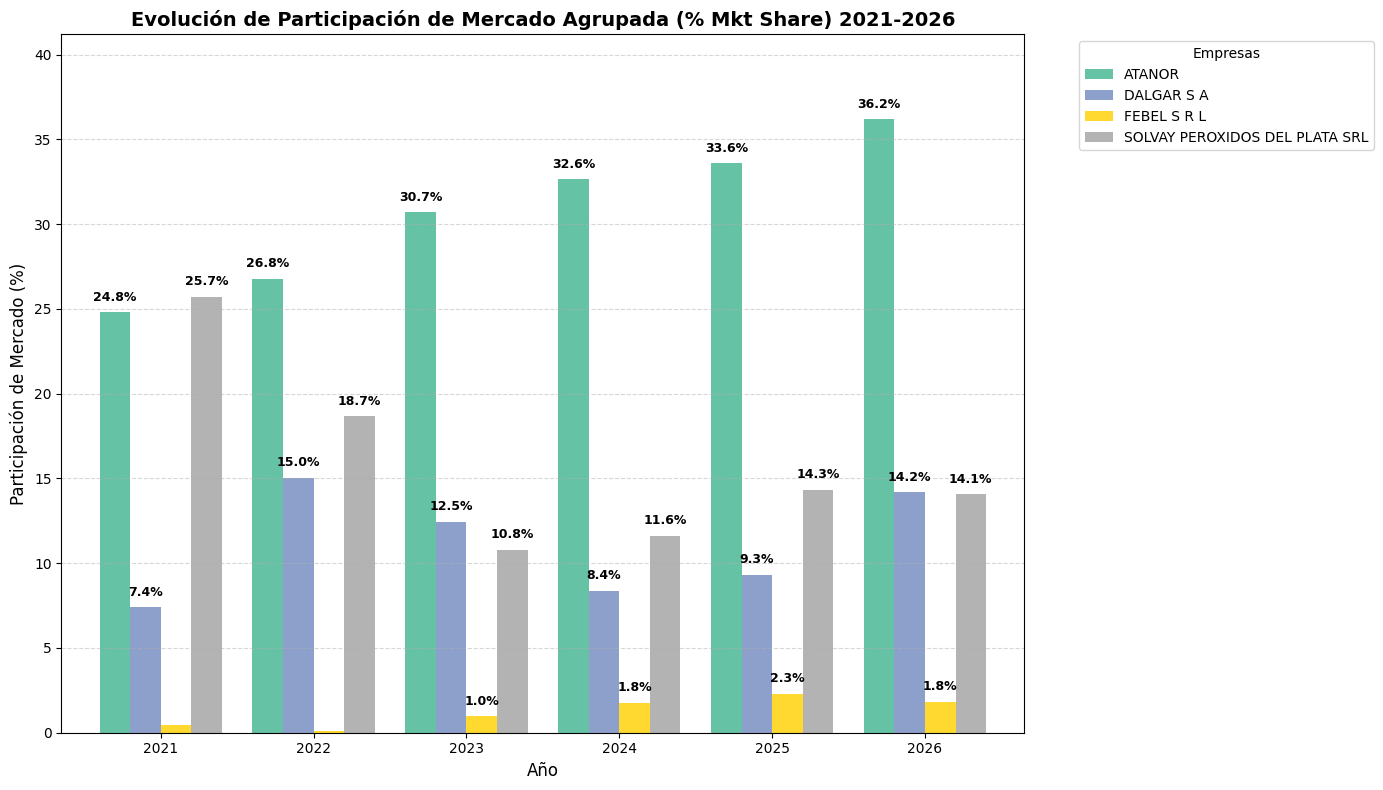

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Asegurar la columna de Año
if 'Anio' not in df.columns:
    df['Anio'] = df['Date'].dt.year

# 2. Agrupar el volumen por Año e Importador
df_mkt = df.groupby(['Anio', 'Importer'])['Net Weight'].sum().reset_index()

# 3. Calcular el volumen total del mercado por año para obtener los porcentajes
totales_anuales = df.groupby('Anio')['Net Weight'].sum().reset_index().rename(columns={'Net Weight': 'Total_Anio'})
df_mkt = pd.merge(df_mkt, totales_anuales, on='Anio')
df_mkt['Porcentaje'] = (df_mkt['Net Weight'] / df_mkt['Total_Anio']) * 100

# 4. Definir las empresas de interés con sus nombres exactos
empresas_interes = [
    'SOLVAY PEROXIDOS DEL PLATA SRL',
    'ATANOR',
    'DALGAR S A',
    'FEBEL S R L'
]

# 5. Filtrar y pivotar para obtener el formato óptimo para gráfico agrupado
df_filtrado = df_mkt[df_mkt['Importer'].isin(empresas_interes)].copy()
df_pivot_mkt = df_filtrado.pivot(index='Anio', columns='Importer', values='Porcentaje').fillna(0)

# 6. Graficar barras agrupadas (stacked=False)
ax = df_pivot_mkt.plot(kind='bar', stacked=False, figsize=(14, 8), colormap='Set2', width=0.8)

plt.title("Evolución de Participación de Mercado Agrupada (% Mkt Share) 2021-2026", fontsize=14, fontweight='bold')
plt.xlabel("Año", fontsize=12)
plt.ylabel("Participación de Mercado (%)", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Empresas", bbox_to_anchor=(1.05, 1), loc='upper left')

# Añadir etiquetas de texto con el porcentaje sobre cada barra correspondiente
for p in ax.patches:
    height = p.get_height()
    if height > 0.5:  # Mostrar etiquetas para valores mayores a 0.5%
        ax.text(p.get_x() + p.get_width() / 2.,
                height + 0.5,
                f'{height:.1f}%',
                ha='center',
                va='bottom',
                fontsize=9,
                fontweight='bold')

plt.ylim(0, df_filtrado['Porcentaje'].max() + 5)
plt.tight_layout()
plt.show()

# Comparación de precios vs competidores (reventa) y la incidencia de los fletes (Obj 2 -3)

Lo importante es medir nuestra competitividad vs.los revendedores que son nuestros competidores directos.
No se hace la comparación de las empresas que mayor cantidad importan, varias de las cuales consumen para uso propio el agua oxigenada.
No se incluyen precios de Atanor (Ver nota en sección Incorporación prod local)

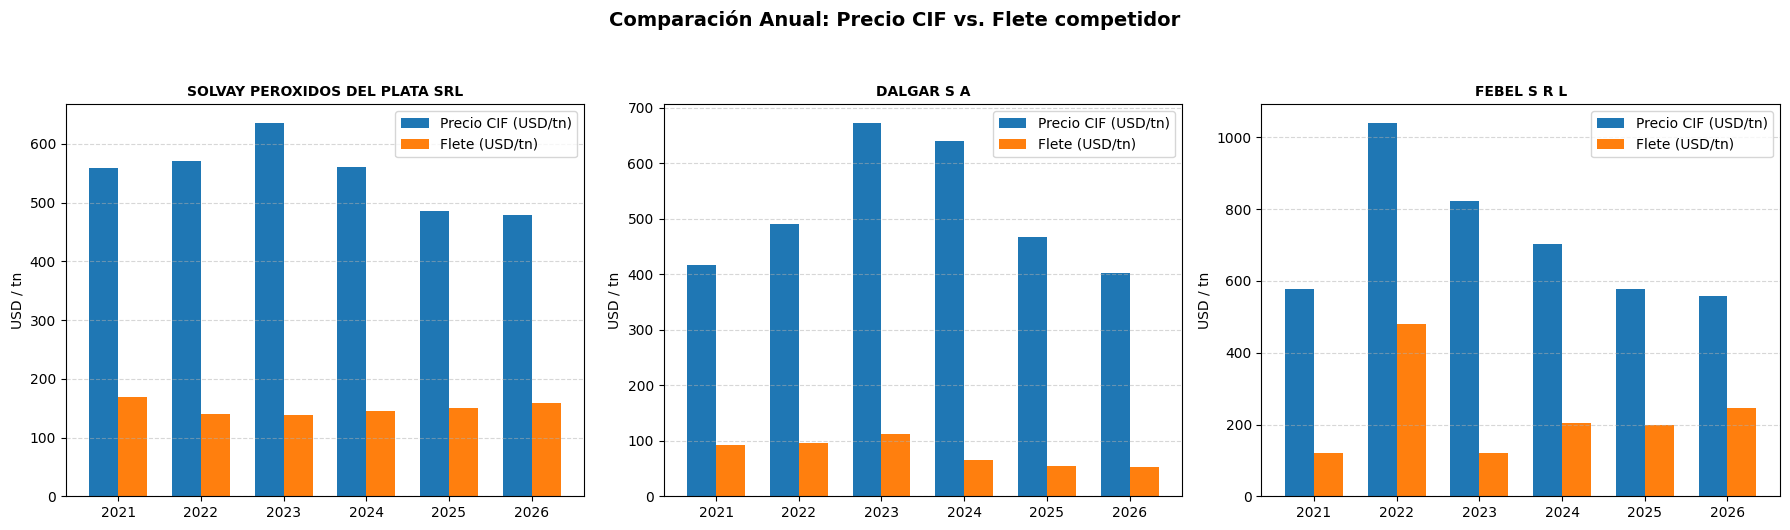

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar el dataset original para excluir a ATANOR
df_imports = df[df['Importer'] != 'ATANOR'].copy()

# Asegurar que la columna Anio está presente
df_imports['Anio'] = df_imports['Date'].dt.year

# 2. Definir las empresas específicas solicitadas (Solvay, Dalgar, y buscar coincidencia para 'FEBEL')
nombre_febel_exacto = [imp for imp in df_imports['Importer'].unique() if 'FEBEL' in str(imp).upper()]
febel_name = nombre_febel_exacto[0] if len(nombre_febel_exacto) > 0 else 'FEBEL S R L'

# Lista final de empresas a mostrar
empresas_seleccionadas = ['SOLVAY PEROXIDOS DEL PLATA SRL', 'DALGAR S A', febel_name]
df_seleccion = df_imports[df_imports['Importer'].isin(empresas_seleccionadas)].copy()

# 3. Agrupar por año e importador para calcular promedios de precios y fletes usando las columnas de toneladas
df_resumen = df_seleccion.groupby(['Anio', 'Importer'])[['Precio CIF USD/tn', 'Freight USD/tn']].mean().reset_index()

# 4. Crear el gráfico comparativo adaptado a la cantidad de empresas seleccionadas
num_empresas = len(empresas_seleccionadas)
fig, axes = plt.subplots(nrows=1, ncols=num_empresas, figsize=(6 * num_empresas, 5), sharex=False)
if num_empresas == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, importer in enumerate(empresas_seleccionadas):
    datos_imp = df_resumen[df_resumen['Importer'] == importer]
    ax = axes[i]

    x = datos_imp['Anio']
    width = 0.35

    ax.bar(x - width/2, datos_imp['Precio CIF USD/tn'], width, label='Precio CIF (USD/tn)', color='#1f77b4')
    ax.bar(x + width/2, datos_imp['Freight USD/tn'], width, label='Flete (USD/tn)', color='#ff7f0e')

    ax.set_title(f"{importer}", fontsize=10, fontweight='bold')
    ax.set_ylabel("USD / tn")

    ax.set_xticks(x)
    ax.set_xticklabels(x.astype(int))

    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend()

plt.suptitle("Comparación Anual: Precio CIF vs. Flete competidor", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


Lo más importante de este gráfico es notar el peso mayor de los fletes de Solvay frente a los de Dalgar, ya que estas dos empresas compiten entre sí por la reventa local de agua oxigenada.
Tanto el precio como el flete de Dalgar son menores porque importa desde Uruguay, mientras Solvay lo hace desde Brasil al igual que Febel. En el último año esta diferencia ha aumentado, lo que muestra que debemos mejorar nuestros costos de producción y buscar mejores opciones de fletes.

In [24]:
df.to_excel("MercadoPeroxlimpio.xlsx", index=False) # Salvar los cambios hechos en todo el análisis en un nuevo dataset limpio en Excel
print("El dataset limpio se guardó como MercadoPeroxlimpio.xlsx")

El dataset limpio se guardó como MercadoPeroxlimpio.xlsx


#Conclusiones del análisis dataset

El mercado argentino de agua oxigenada viene cayendo sin pausa desde 2023, lo que muestra una relación directa con la caída del consumo y la actividad industrial.
La incidencia de los fletes ha aumentado dado que los precios bajaron mientras nuestros transportes (Solvay Peróxidos) se mantuvieron casi constantes desde 2021 en USD/tn.
Frente a este contexto se buscará importar producto desde Chile por la menor distancia respecto a Brasil.
Respecto al market share se mantiene relativamente constante, con un volumen de mercado menor para todos, lo que también explica la baja de precios.



## KPI y otras conclusiones -> se incluirán en dashboard PWR BI